# 4. Predict popularity among known hits

Filter the saved training and holdout partitions separately to popularity > 70. Never train on a hit from the shared holdout. Compare the same eight regressors with a high-popularity training-mean baseline.

In [1]:
from pipeline_lib import RunContext, train_models
ctx = RunContext.from_environment("regression_high")
print("Profile:", ctx.config["profile"])
print("Artifacts:", ctx.run_dir)
from IPython.display import Image, display
train, holdout = ctx.data()
print('High-popularity training rows:', (train.popularity > ctx.config['hit_threshold']).sum())
print('High-popularity holdout rows:', (holdout.popularity > ctx.config['hit_threshold']).sum())

Profile: full
Artifacts: /Users/anishech/Projects/ML_Spotify/runs/20261021_141923_142263_full
High-popularity training rows: 1825
High-popularity holdout rows: 456


The popularity range is narrow, so a small absolute error or high ±5 percentage may still have weak R². This model estimates scores conditional on being a hit. The combined stage will also encounter classifier false positives, which this model has not been trained to represent.

In [2]:
high_results = train_models(ctx, high_only=True)
display(high_results)

START Lasso: 30 candidates x 5 folds + refit; train=1825 holdout=456


Fitting 5 folds for each of 30 candidates, totalling 150 fits


DONE Lasso: CV neg_rmse=-4.4463; holdout {'rows': 456, 'mae': 3.26529647613936, 'rmse': 4.047312837561034, 'r2': 0.24251042488301555, 'within_5_percent': 82.45614035087719}; 1.3s


START Ridge: 30 candidates x 5 folds + refit; train=1825 holdout=456


[CV] END model__alpha=0.3593813663804629, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.3593813663804629, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.3593813663804629, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.3593813663804629, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.3593813663804629, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.012618568830660211, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.012618568830660211, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total time=   0.0s
[CV] END model__alpha=0.012618568830660211, model__max_iter=5000, model__selection=cyclic, model__tol=0.001; total

...

[CV] END model__colsample_bytree=0.8, model__gamma=0.2, model__learning_rate=0.01, model__max_depth=6, model__n_estimators=400, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.9; total time=   0.4s
[CV] END model__colsample_bytree=0.8, model__gamma=0.2, model__learning_rate=0.01, model__max_depth=6, model__n_estimators=400, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.9; total time=   0.4s
[CV] END model__colsample_bytree=0.8, model__gamma=0.2, model__learning_rate=0.01, model__max_depth=6, model__n_estimators=400, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.9; total time=   0.4s
[CV] END model__colsample_bytree=0.6, model__gamma=0, model__learning_rate=0.005, model__max_depth=4, model__n_estimators=500, model__reg_alpha=0.1, model__reg_lambda=1.5, model__subsample=0.8; total time=   0.2s
[CV] END model__colsample_bytree=0.6, model__gamma=0, model__learning_rate=0.005, model__max_depth=4, model__n_estimators=500, model__reg_alpha=0.1, mo

[CV] END model__colsample_bytree=0.8, model__gamma=0, model__learning_rate=0.005, model__max_depth=7, model__n_estimators=400, model__reg_alpha=0, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.6s
[CV] END model__colsample_bytree=0.8, model__gamma=0, model__learning_rate=0.005, model__max_depth=7, model__n_estimators=400, model__reg_alpha=0, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.6s
[CV] END model__colsample_bytree=0.8, model__gamma=0, model__learning_rate=0.005, model__max_depth=7, model__n_estimators=400, model__reg_alpha=0, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.6s
[CV] END model__colsample_bytree=0.8, model__gamma=0, model__learning_rate=0.005, model__max_depth=7, model__n_estimators=400, model__reg_alpha=0, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.6s
[CV] END model__colsample_bytree=0.8, model__gamma=0, model__learning_rate=0.005, model__max_depth=7, model__n_estimators=400, model__reg_alpha=0, model__re

DONE XGBRegressor: CV neg_rmse=-4.5284; holdout {'rows': 456, 'mae': 3.430112838745117, 'rmse': 4.239536869378693, 'r2': 0.1688489317893982, 'within_5_percent': 81.14035087719299}; 5.5s


Selected ElasticNet using neg_rmse from training folds only


,model,cv_selection_score,test_rows,test_mae,test_rmse,test_r2,test_within_5_percent,seconds,train_rows,train_mae,train_rmse,train_r2,train_within_5_percent
0,MeanBaseline,NaN,456,3.873341,4.654639,-0.001879,69.517544,NaN,NaN,NaN,NaN,NaN,NaN
1,Lasso,-4.446316,456,3.265296,4.047313,0.242510,82.456140,1.288886,1825.0,3.326704,4.295885,0.223516,79.780822
2,Ridge,-4.447048,456,3.259327,4.043791,0.243828,82.236842,0.146328,1825.0,3.321105,4.290856,0.225333,79.452055
3,ElasticNet,-4.446182,456,3.267709,4.049557,0.241670,82.236842,0.127891,1825.0,3.328034,4.296877,0.223158,79.780822
4,RandomForestRegressor,-4.513296,456,3.384533,4.202852,0.183171,81.359649,20.455372,1825.0,2.847905,3.694084,0.425830,86.301370
5,GradientBoostingRegressor,-4.518795,456,3.430209,4.232107,0.171760,81.578947,17.877602,1825.0,3.141180,3.998971,0.327142,83.835616
6,AdaBoostRegressor,-4.570755,456,3.566260,4.348983,0.125382,80.043860,9.355900,1825.0,3.493527,4.401706,0.184791,80.109589
7,KNeighborsRegressor,-4.627135,456,3.464620,4.357363,0.122008,78.728070,0.240947,1825.0,3.234667,4.216081,0.252098,81.205479
8,XGBRegressor,-4.528357,456,3.430113,4.239537,0.168849,81.140351,5.547053,1825.0,3.191637,4.072509,0.302168,83.561644


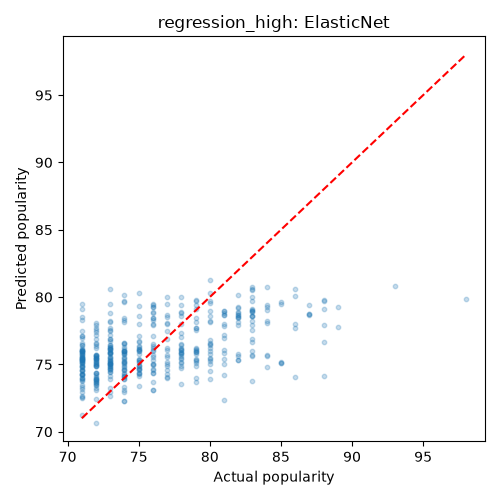

In [3]:
display(Image(filename=str(ctx.path('plots', 'regression_high_predictions.png'))))

The best complete high-popularity regression pipeline is saved under `models/regression_high_best.joblib`. Selection uses training cross-validation only.